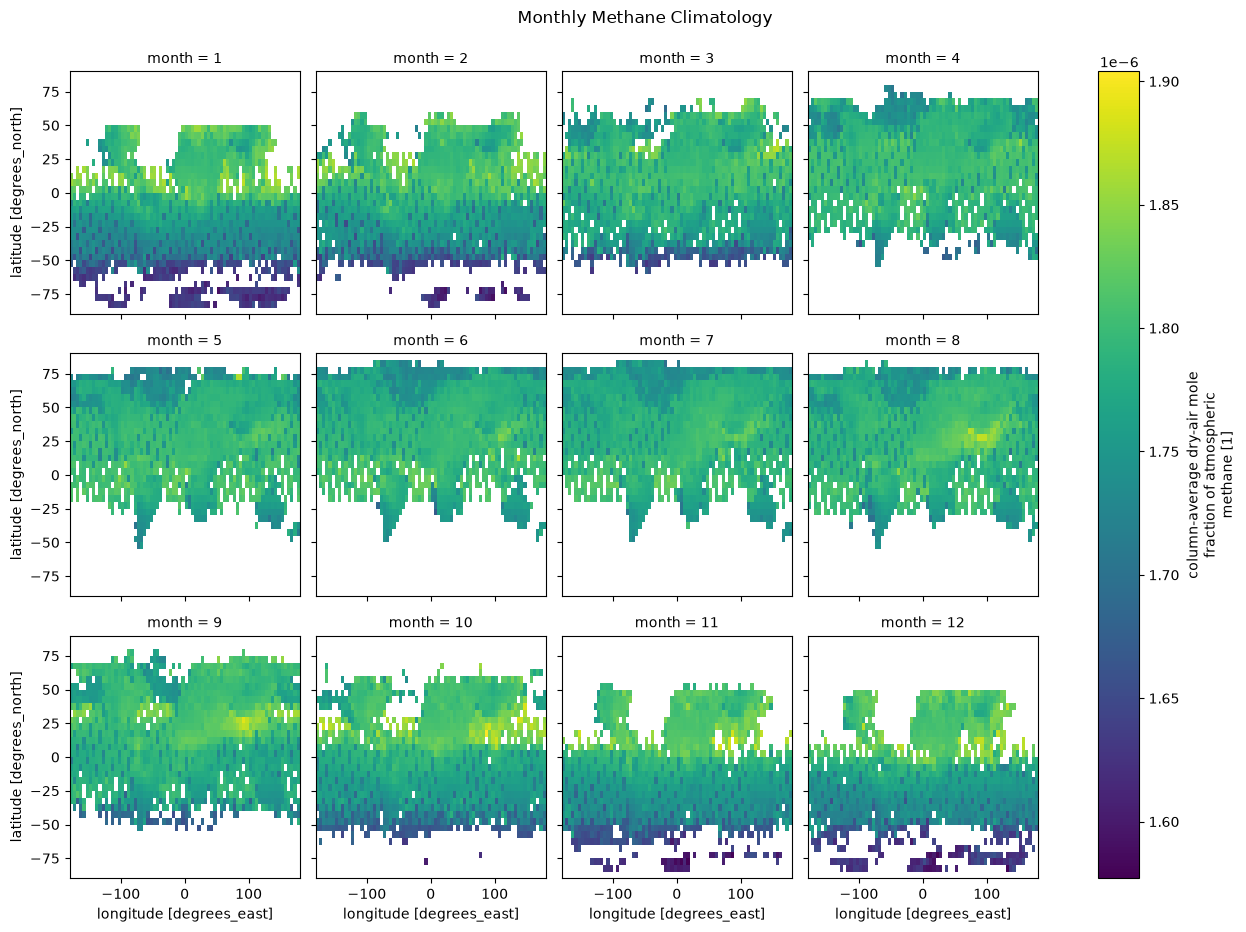

In [4]:
# 第一题代码
import xarray as xr
import matplotlib.pyplot as plt

#1.1
# 读取数据
ds = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
ch4 = ds["xch4"]
# 去除缺失的数据
ch4 = ch4.where(ch4 < 1e19)
# 计算12个月的气候态
monthly = ch4.groupby("time.month").mean(dim="time")
# 绘制12张图
g = monthly.plot(
    x="lon",
    y="lat",
    col="month",
    col_wrap=4,
    cmap="viridis"
)
g.fig.suptitle("Monthly Methane Climatology", y=1.03)
plt.show()


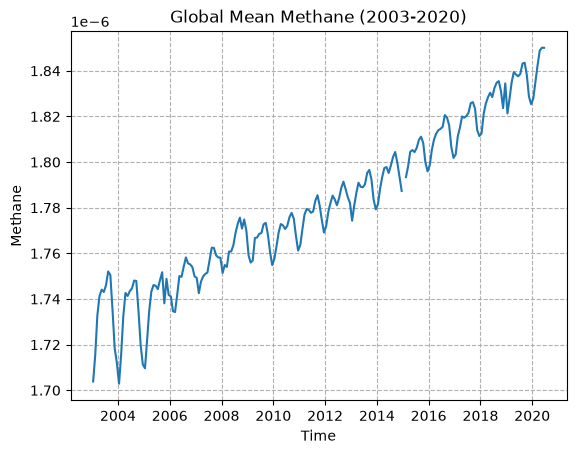

In [17]:
# 1.2代码
# 计算全球每个月的平均甲烷浓度
global_ch4 = ch4.mean(dim=["lat", "lon"])
# 绘制时间序列图
global_ch4.plot()
# 添加标题和坐标轴名称
plt.title("Global Mean Methane (2003-2020)")
plt.xlabel("Time")
plt.ylabel("Methane")
plt.grid(linestyle="--")
plt.show()


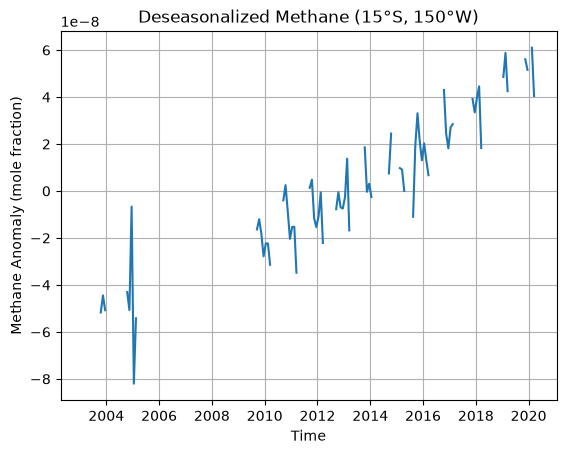

In [19]:
# 1.3代码
# 找到经纬度
point = ch4.sel(lat=-15, lon=-150, method="nearest")
# 计算每个月的多年平均浓度
monthly_mean = point.groupby("time.month").mean(dim="time")
# 去除季节性变化
de = point.groupby("time.month") - monthly_mean
# 绘制时间序列
de.plot()

plt.title("Deseasonalized Methane (15°S, 150°W)")
plt.xlabel("Time")
plt.ylabel("Methane Anomaly (mole fraction)")
plt.grid(True)
plt.show()


<xarray.Dataset> Size: 44MB
Dimensions:  (time: 684, lat: 89, lon: 180)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 356B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lat, lon) float32 44MB ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...


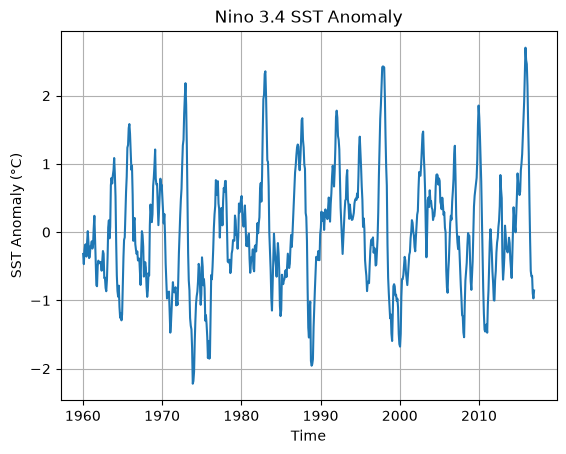

In [16]:
# 第二题代码
# 2.1
import xarray as xr
import matplotlib.pyplot as plt

# 引入nc文件
ds = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
print(ds)
# 提取数据
sst = ds["sst"]
sst_region = sst.sel(
    lat=slice(-5, 5),
    lon=slice(190, 240)
)
# 计算区域平均海表温度
sst_mean = sst_region.mean(dim=["lat", "lon"])
# 计算每个月的气候态
climatology = sst_mean.groupby("time.month").mean(dim="time")
# 计算海表温度距平
anomaly = sst_mean.groupby("time.month") - climatology

# 绘制距平时间序列
anomaly.plot()
plt.title("Nino 3.4 SST Anomaly")
plt.xlabel("Time")
plt.ylabel("SST Anomaly (°C)")
plt.grid(True)
plt.show()

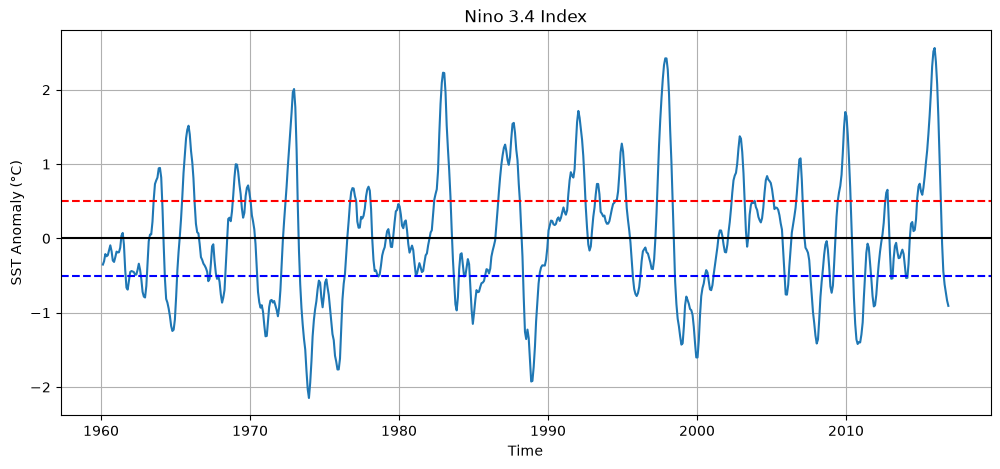

In [22]:
# 2.2
# 计算3个月滑动平均
nino34 = anomaly.rolling(time=3, center=True).mean()
nino34.plot(figsize=(12, 5))
# 添加参考线
plt.axhline(y=0, color="black")
plt.axhline(y=0.5, color="red", linestyle="--")
plt.axhline(y=-0.5, color="blue", linestyle="--")

plt.title("Nino 3.4 Index")
plt.xlabel("Time")
plt.ylabel("SST Anomaly (°C)")

plt.grid(True)
plt.show()


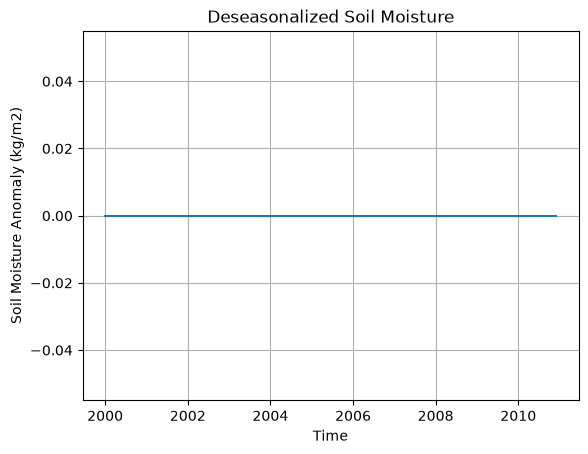

In [17]:
# 第三题
# 3.1
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# 批量读取并合并所有月份的数据
data = xr.open_mfdataset("GLDAS_NOAH025_M.A*.021.nc4",)
# 选择范围
soil = soil.where(
    (soil.lat >= 18) & (soil.lat <= 28),
    drop=True
)
soil = soil.where(
    (soil.lon >= 108) & (soil.lon <= 118),
    drop=True
)
# 提取土壤
soil = data["SoilMoi10_40cm_inst"]
# 计算区域平均土壤
soil_mean = soil.mean(dim=["lat", "lon"])
# 计算每个月的多年平均值
climatology = soil_mean.groupby("time.month").mean(dim="time")
# 去除月度季节周期
anomaly = soil_mean.groupby("time.month") - climatology
# 绘制去季节化时间序列
anomaly.plot()

plt.title("Deseasonalized Soil Moisture")
plt.xlabel("Time")
plt.ylabel("Soil Moisture Anomaly (kg/m2)")
plt.grid(True)
plt.show()



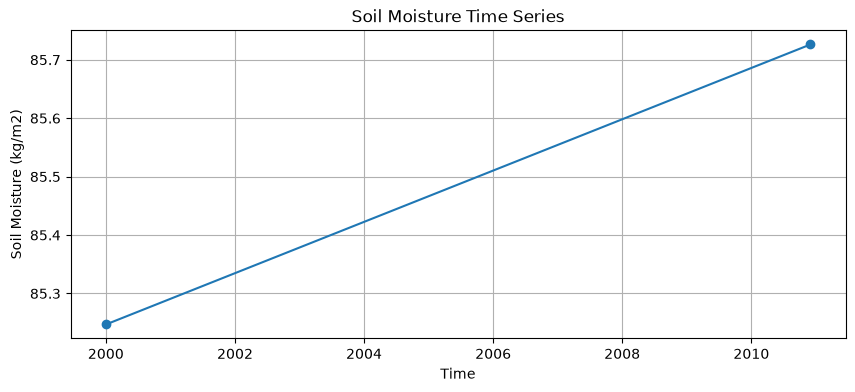

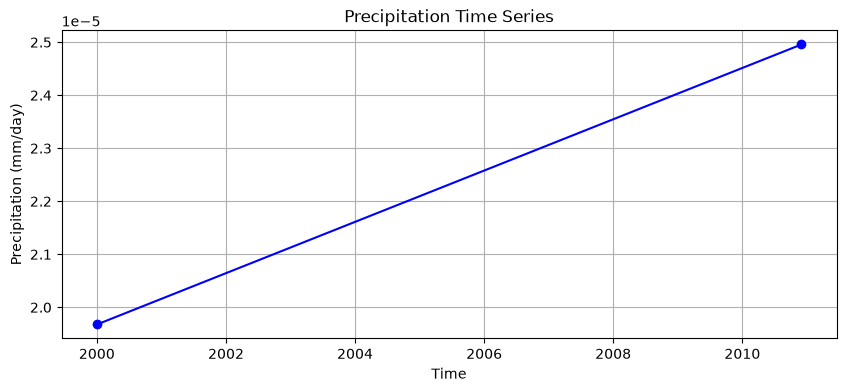

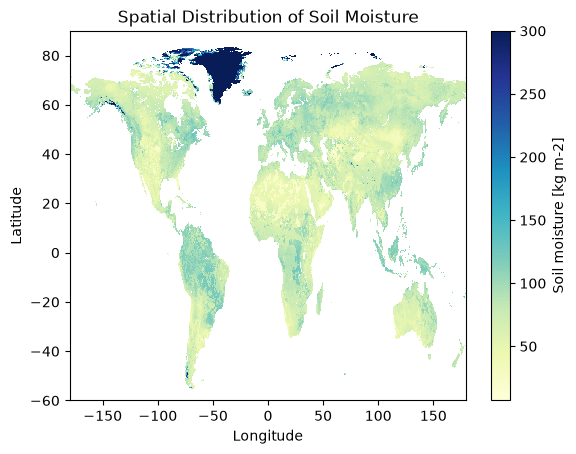

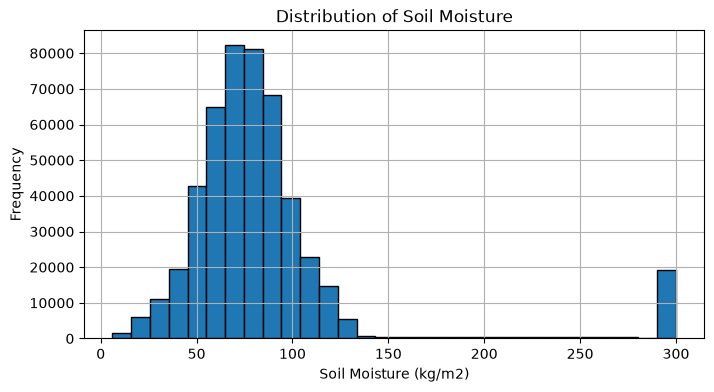

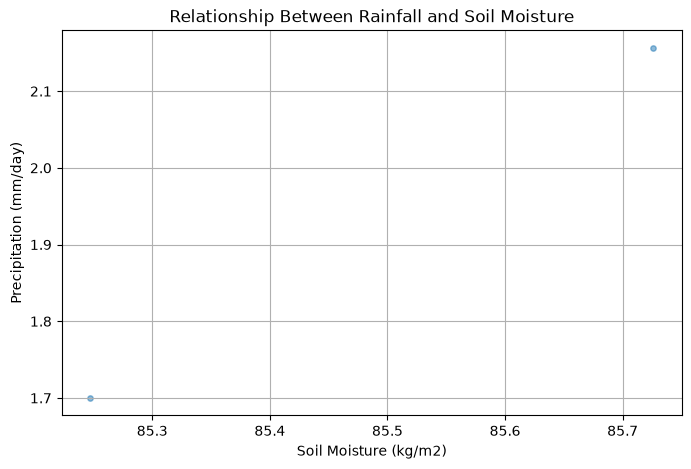

In [15]:
# 3.2
# 图1：土壤时间序列
plt.figure(figsize=(10, 4))
plt.plot(
    soil_mean.time,
    soil_mean,
    marker="o"
)
plt.title("Soil Moisture Time Series")
plt.xlabel("Time")
plt.ylabel("Soil Moisture (kg/m2)")
plt.grid(True)
plt.show()

# 图2：降水时间序列
# 提取降水数据
rain = data["Rainf_f_tavg"]
rain = rain.sel(
    lat=slice(18, 28),
    lon=slice(108, 118)
)
rain_mean = rain.mean(dim=["lat", "lon"])
plt.figure(figsize=(10, 4))
plt.plot(
    rain_mean.time,
    rain_mean,
    marker="o",
    color="blue"
)
plt.title("Precipitation Time Series")
plt.xlabel("Time")
plt.ylabel("Precipitation (mm/day)")
plt.grid(True)
plt.show()

# 图3：土壤空间分布图
soil_map = soil.mean(dim="time")
soil_map.plot(
    x="lon",
    y="lat",
    cmap="YlGnBu"
)
plt.title("Spatial Distribution of Soil Moisture")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# 图4：土壤直方图
soil_values = soil.values.flatten()
soil_values = soil_values[np.isfinite(soil_values)]
plt.figure(figsize=(8, 4))
plt.hist(
    soil_values,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Soil Moisture")
plt.xlabel("Soil Moisture (kg/m2)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

# 图5：降水与土壤散点图
# 分别计算每个月的区域平均值
soil_mean = soil.mean(dim=["lat", "lon"], skipna=True)
rain_mean = rain.mean(dim=["lat", "lon"], skipna=True)

# 按照相同时间进行匹配
soil_mean, rain_mean = xr.align(
    soil_mean,
    rain_mean,
    join="inner"
)

# 去除无效数据
valid = (
    np.isfinite(soil_mean.values) &
    np.isfinite(rain_mean.values)
)

# 绘制散点图
plt.figure(figsize=(8, 5))

plt.scatter(
    soil_mean.values[valid],
    rain_mean.values[valid] * 86400,
    alpha=0.5,
    s=15
)

# 设置标题和坐标轴
plt.title("Relationship Between Rainfall and Soil Moisture")
plt.xlabel("Soil Moisture (kg/m2)")
plt.ylabel("Precipitation (mm/day)")

plt.grid(True)
plt.show()